# Kết quả mô hình dự đoán lương IT

Notebook này **chỉ trình bày** kết quả đã có trong `reports/` và `models/model_card.json`: không huấn luyện, không đọc tập test thô và không chấm lại tập test. Mọi con số đều sinh ra bởi các lệnh trong README:

| Bước | Lệnh | File kết quả |
|---|---|---|
| GĐ4 – chọn mô hình | `python src/train.py --stage gd4` | `gd4_grid_results.csv`, `gd4_ablation.csv`, `gd4_selected_model.json` |
| Nested CV | `python src/train.py --stage nested` | `gd4_nested_cv.csv` |
| GĐ5 – đánh giá test | `python src/evaluate.py` | `gd5_*.csv`, `test_set_log.csv`, `models/model_card.json` |

Chạy lại notebook: `jupyter notebook notebooks/03_ket_qua_mo_hinh.ipynb` rồi *Run All*. Không cần dữ liệu gốc.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
REPORTS = ROOT / "reports"
sys.path.insert(0, str(ROOT / "src"))
from intervals import apply_interval  # noqa: E402

card = json.loads((ROOT / "models" / "model_card.json").read_text(encoding="utf-8"))
selected = json.loads((REPORTS / "gd4_selected_model.json").read_text(encoding="utf-8"))
read = lambda name: pd.read_csv(REPORTS / name, encoding="utf-8-sig")

# Màu: xanh = mô hình được chọn / mô hình; xám = baseline, phần phụ; cam = điểm cần chú ý
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
GRAY, INK, MUTED = "#a3a29c", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GRAY, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
})
FAMILY_VI = {"linear_regression": "Linear Regression", "ridge": "Ridge",
             "decision_tree": "Decision Tree", "random_forest": "Random Forest",
             "dummy_median": "Baseline trung vị"}
print(f"Mô hình được chọn: {FAMILY_VI[card['model']]} {card['params']}")
print(f"Train {card['n_train']} tin, test {card['n_test']} tin; tập test đã được chấm {card['test_set_uses']} lần")

Mô hình được chọn: Linear Regression {'skill_top_k': 0, 'experience': 'numeric', 'log_target': False}
Train 370 tin, test 86 tin; tập test đã được chấm 5 lần


## 1. Từ 48.092 bản ghi đến 456 tin có nhãn

Phần lớn bản ghi bị loại vì không phải tin IT hoặc không ghi lương cụ thể ("Thỏa thuận"). Đây là giới hạn lớn nhất của dự án: mô hình chỉ học từ 370 tin train.

In [2]:
funnel = read("gd1b_funnel.csv").rename(columns={"Unnamed: 0": "buoc"})
funnel = funnel.set_index(funnel.columns[0])[["it_final"]].rename(columns={"it_final": "số bản ghi"})
display(funnel)

,số bản ghi
buoc,
0. Tổng bản ghi VietJobs,48092
1. country == Việt Nam,47957
2. thuộc IT,1915
3. có lương (bỏ 0.0 = thỏa thuận),1129
"4. dạng khoảng a–b hợp lệ (bỏ điểm đơn, 0–b, a>b)",990
5. hợp đồng Toàn thời gian,961
6. 3 ≤ min và max ≤ 200 triệu,952
7. sau gộp trùng (tiêu đề+địa điểm+lương+mô tả),852


## 2. So sánh mô hình và quy tắc chọn 1-SE

Mỗi họ mô hình được chỉnh tham số bằng GroupKFold 5 fold trên tập train (236 cấu hình). Thanh ngang là MAE cross-validation của cấu hình tốt nhất mỗi họ, vạch đen là ±1 sai số chuẩn (SE).

**Quy tắc 1-SE:** lấy MAE nhỏ nhất cộng 1 SE của chính cấu hình đó làm ngưỡng, rồi chọn cấu hình *đơn giản nhất* có MAE dưới ngưỡng. Các mô hình chênh nhau ít hơn độ dao động giữa các fold, nên mô hình đơn giản được ưu tiên.

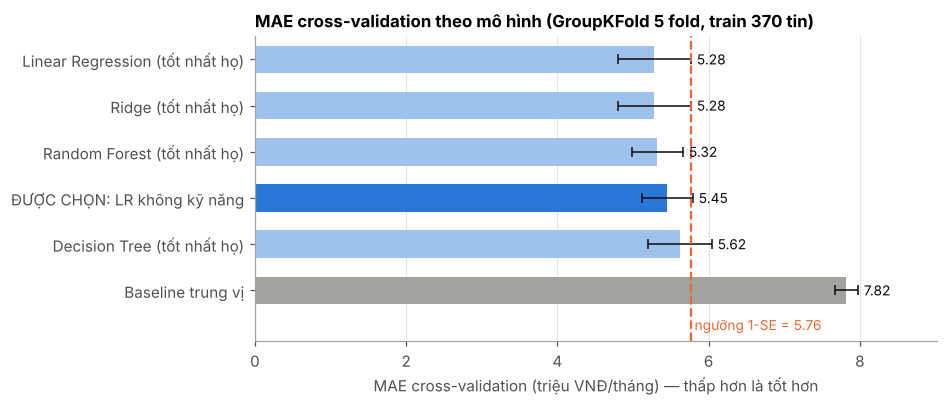

,mô hình,MAE CV,SE,R²
0,Baseline trung vị,7.820,0.153,-0.047
1,Decision Tree (tốt nhất họ),5.619,0.421,0.390
2,ĐƯỢC CHỌN: LR không kỹ năng,5.451,0.338,0.438
3,Random Forest (tốt nhất họ),5.324,0.336,0.454
4,Ridge (tốt nhất họ),5.281,0.483,0.436
5,Linear Regression (tốt nhất họ),5.281,0.483,0.436


In [3]:
res = read("model_results.csv")
best = res[res.stage == "gd4"].copy()
best["ten"] = best.model.map(FAMILY_VI) + " (tốt nhất họ)"
dummy = res[(res.model == "dummy_median") & (res.stage == "cv_train")].assign(ten="Baseline trung vị")
chosen = res[(res.stage == "cv_train") & (res.model == card["model"])].assign(ten="ĐƯỢC CHỌN: LR không kỹ năng")
tab = pd.concat([dummy, best, chosen])[["ten", "mae_mean", "mae_se", "r2_mean"]]
tab = tab.sort_values("mae_mean", ascending=False).reset_index(drop=True)

threshold = selected["threshold"]
fig, ax = plt.subplots(figsize=(8, 3.6))
colors = [BLUE if t.startswith("ĐƯỢC") else (GRAY if t.startswith("Baseline") else "#9ec2ee") for t in tab.ten]
ax.barh(tab.ten, tab.mae_mean, xerr=tab.mae_se, color=colors, height=0.6,
        error_kw={"ecolor": INK, "elinewidth": 1, "capsize": 3})
for i, r in tab.iterrows():
    ax.text(r.mae_mean + r.mae_se + 0.08, i, f"{r.mae_mean:.2f}", va="center", color=INK, fontsize=9)
ax.axvline(threshold, color=ORANGE, lw=1.5, ls="--")
ax.text(threshold + 0.05, -0.75, f"ngưỡng 1-SE = {threshold:.2f}", color=ORANGE, fontsize=9, va="center")
ax.set_ylim(-1.1, len(tab) - 0.5)
ax.set_xlabel("MAE cross-validation (triệu VNĐ/tháng) — thấp hơn là tốt hơn")
ax.set_xlim(0, tab.mae_mean.max() + 1.2)
ax.grid(axis="y", visible=False)
ax.set_title("MAE cross-validation theo mô hình (GroupKFold 5 fold, train 370 tin)")
plt.show()
display(tab.rename(columns={"ten": "mô hình", "mae_mean": "MAE CV", "mae_se": "SE", "r2_mean": "R²"}).round(3))

### Vì sao bỏ quy tắc 1-SD cũ

Trước đây dự án dùng ngưỡng MAE nhỏ nhất + 1 **độ lệch chuẩn** (SD). SD lớn gấp √5 ≈ 2,2 lần SE, nên ngưỡng rộng đến mức **mọi cấu hình đều lọt**, quy tắc mất tác dụng chọn lọc. Biểu đồ dưới đây vẽ MAE của cả 236 cấu hình cùng hai ngưỡng.

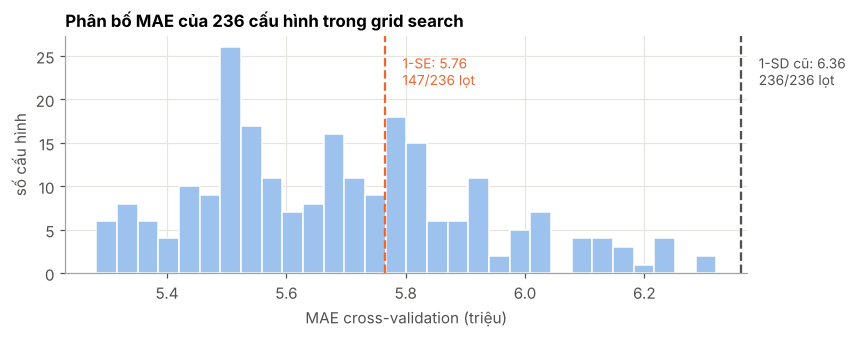

In [4]:
grid = read("gd4_grid_results.csv")
best_row = grid.loc[grid.mae_mean.idxmin()]
thr_se, thr_sd = best_row.mae_mean + best_row.mae_se, best_row.mae_mean + best_row.mae_std
n_se, n_sd = (grid.mae_mean <= thr_se).sum(), (grid.mae_mean <= thr_sd).sum()

fig, ax = plt.subplots(figsize=(8, 2.8))
ax.hist(grid.mae_mean, bins=30, color="#9ec2ee", edgecolor="white", linewidth=1)
for x, c, lab in ((thr_se, ORANGE, f"1-SE: {thr_se:.2f}\n{n_se}/{len(grid)} lọt"),
                  (thr_sd, MUTED, f"1-SD cũ: {thr_sd:.2f}\n{n_sd}/{len(grid)} lọt")):
    ax.axvline(x, color=c, lw=1.5, ls="--")
    ax.text(x + 0.03, ax.get_ylim()[1] * 0.92, lab, color=c, fontsize=9, va="top")
ax.set_xlabel("MAE cross-validation (triệu)")
ax.set_ylabel("số cấu hình")
ax.set_title(f"Phân bố MAE của {len(grid)} cấu hình trong grid search")
plt.show()

## 3. Kỹ năng có giúp dự đoán không? (ablation)

Với mỗi họ mô hình, lấy cấu hình tốt nhất ứng với từng số kỹ năng `skill_top_k` (0 = không dùng kỹ năng). Vì mọi cấu hình dùng **cùng 5 fold**, chênh lệch được so theo cặp fold; "rõ" nghĩa là chênh quá 2 SE của chênh lệch.

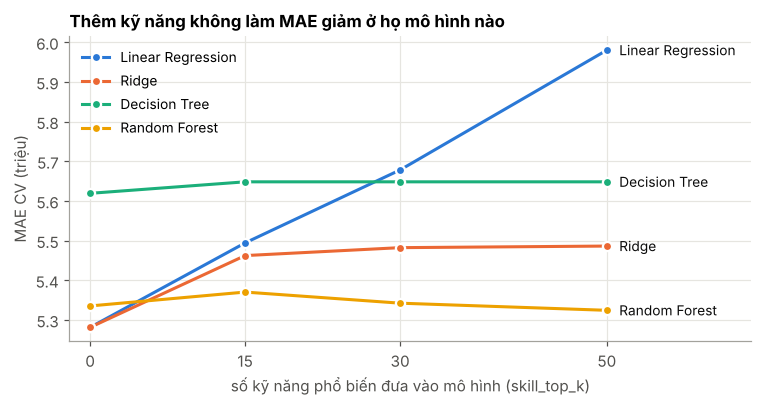

,lựa chọn,họ mô hình,giá trị,MAE CV,chênh so với tham chiếu,SE chênh,kết luận
0,skill_top_k,linear_regression,0,5.281,0.000,0.000,tham chiếu
1,skill_top_k,linear_regression,15,5.494,0.212,0.042,kém hơn rõ
2,skill_top_k,linear_regression,30,5.678,0.397,0.222,không khác rõ
3,skill_top_k,linear_regression,50,5.980,0.699,0.386,không khác rõ
4,skill_top_k,ridge,0,5.281,0.000,0.000,tham chiếu
5,skill_top_k,ridge,15,5.462,0.180,0.053,kém hơn rõ
6,skill_top_k,ridge,30,5.482,0.200,0.175,không khác rõ
7,skill_top_k,ridge,50,5.486,0.205,0.207,không khác rõ
8,skill_top_k,decision_tree,0,5.619,0.000,0.000,tham chiếu
9,skill_top_k,decision_tree,15,5.648,0.029,0.224,không khác rõ


In [5]:
abl = read("gd4_ablation.csv")
sk = abl[abl.lua_chon == "skill_top_k"].copy()
sk["gia_tri"] = sk.gia_tri.astype(int)

fig, ax = plt.subplots(figsize=(8, 3.6))
for fam, color in zip(["linear_regression", "ridge", "decision_tree", "random_forest"],
                      [BLUE, ORANGE, AQUA, YELLOW]):
    d = sk[sk.ho_mo_hinh == fam].sort_values("gia_tri")
    ax.plot(d.gia_tri, d.mae_cv, marker="o", ms=6, lw=2, color=color, label=FAMILY_VI[fam],
            markeredgecolor="white", markeredgewidth=1.5)
    last = d.iloc[-1]
    ax.text(last.gia_tri + 1.2, last.mae_cv, FAMILY_VI[fam], color=INK, fontsize=9, va="center")
ax.set_xticks([0, 15, 30, 50])
ax.set_xlim(-2, 64)
ax.set_xlabel("số kỹ năng phổ biến đưa vào mô hình (skill_top_k)")
ax.set_ylabel("MAE CV (triệu)")
ax.legend(loc="upper left", frameon=False, fontsize=9)
ax.set_title("Thêm kỹ năng không làm MAE giảm ở họ mô hình nào")
plt.show()

show = abl[["lua_chon", "ho_mo_hinh", "gia_tri", "mae_cv", "chenh_so_voi_tham_chieu", "se_chenh", "ket_luan"]]
display(show.rename(columns={"lua_chon": "lựa chọn", "ho_mo_hinh": "họ mô hình", "gia_tri": "giá trị",
                             "mae_cv": "MAE CV", "chenh_so_voi_tham_chieu": "chênh so với tham chiếu",
                             "se_chenh": "SE chênh", "ket_luan": "kết luận"}))

**Đọc kết quả:**

- Với Linear Regression và Ridge, thêm 15 kỹ năng làm MAE **tăng rõ** (khoảng +0,2 triệu, SE chỉ khoảng 0,05). Thêm 30–50 kỹ năng cũng không tốt hơn.
- Với Decision Tree và Random Forest, có hay không có kỹ năng gần như như nhau.
- Kết luận: với 370 tin train, danh sách kỹ năng trên tin tuyển dụng **không cho thêm thông tin về lương** ngoài nhóm nghề, kinh nghiệm, cấp bậc và thành phố. Đây là kết luận về dữ liệu này, không phải về giá trị của kỹ năng ngoài thị trường.
- Log(lương) và kinh nghiệm dạng nhóm tốt hơn khoảng 0,17 triệu nhưng SE xấp xỉ 0,18, **chưa đủ bằng chứng** để chọn.

## 4. Nested cross-validation: sai số của cả quy trình

Nested CV chạy lại **toàn bộ** GĐ4 (236 cấu hình + quy tắc 1-SE) bên trong từng fold ngoài, rồi chấm trên phần còn lại của fold. Chỉ dùng tập train, không đụng tập test. Đây là con số sai số đáng tin nhất của dự án.

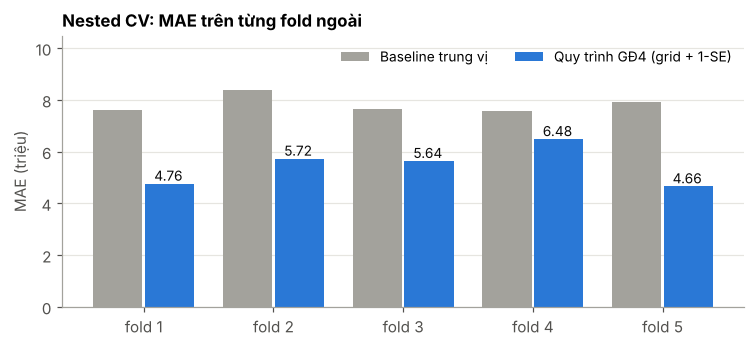

,cách chọn,MAE TB,SD,R² TB
0,Quy trình GĐ4 (grid + 1-SE),5.451,0.756,0.438
1,Chọn cấu hình MAE CV nhỏ nhất,5.442,0.669,0.422
2,Baseline trung vị,7.820,0.343,-0.047


Cấu hình 1-SE chọn ở từng fold ngoài:
cau_hinh_chon_1se
linear_regression {"skill_top_k": 0, "experience": "numeric", "log_target": false}    5


In [6]:
nest = read("gd4_nested_cv.csv")
fig, ax = plt.subplots(figsize=(8, 3.2))
x = np.arange(len(nest))
w = 0.38
ax.bar(x - w / 2 - 0.01, nest.mae_dummy, w, color=GRAY, label="Baseline trung vị")
ax.bar(x + w / 2 + 0.01, nest.mae_chon_1se, w, color=BLUE, label="Quy trình GĐ4 (grid + 1-SE)")
for xi, v in zip(x, nest.mae_chon_1se):
    ax.text(xi + w / 2, v + 0.12, f"{v:.2f}", ha="center", fontsize=9, color=INK)
ax.set_xticks(x, [f"fold {i}" for i in nest.fold])
ax.set_ylabel("MAE (triệu)")
ax.grid(axis="x", visible=False)
ax.legend(frameon=False, fontsize=9, loc="upper right", ncol=2)
ax.set_ylim(0, nest.mae_dummy.max() * 1.25)
ax.set_title("Nested CV: MAE trên từng fold ngoài")
plt.show()

summary = pd.DataFrame({
    "cách chọn": ["Quy trình GĐ4 (grid + 1-SE)", "Chọn cấu hình MAE CV nhỏ nhất", "Baseline trung vị"],
    "MAE TB": [nest.mae_chon_1se.mean(), nest.mae_tot_nhat_cv.mean(), nest.mae_dummy.mean()],
    "SD": [nest.mae_chon_1se.std(), nest.mae_tot_nhat_cv.std(), nest.mae_dummy.std()],
    "R² TB": [nest.r2_chon_1se.mean(), nest.r2_tot_nhat_cv.mean(), nest.r2_dummy.mean()],
}).round(3)
display(summary)
print("Cấu hình 1-SE chọn ở từng fold ngoài:")
print(nest.cau_hinh_chon_1se.value_counts().to_string())

**Đọc kết quả:**

- Cả 5 fold ngoài đều chọn **cùng một cấu hình**, nên quy trình chọn mô hình ổn định.
- Vòng ngoài dùng đúng 5 fold của GĐ4, nên MAE nested (5,45) trùng với MAE CV của mô hình được chọn. Điều này cho thấy việc chọn mô hình **không làm sai số bị ước lượng thấp đi**.
- Chọn theo 1-SE gần như bằng chọn cấu hình có MAE CV nhỏ nhất: chọn mô hình đơn giản không làm mất độ chính xác.
- So với baseline trung vị, sai số giảm khoảng 30%.

## 5. Trên tập test

Tập test gồm 86 tin, không tin nào trùng nhóm tin đăng lại với train. Mô hình được chọn hoàn toàn bằng CV trên train trước khi chấm test. Khoảng ~80% là khoảng dự đoán học từ phần dư out-of-fold trên train (xem mục 6).

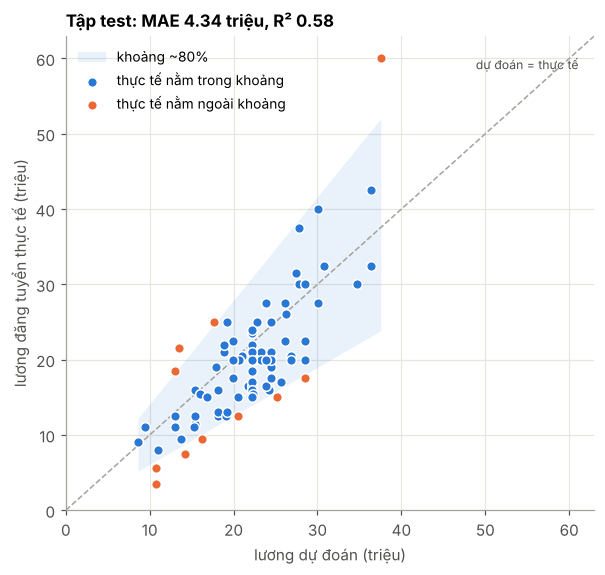

MAE test 4.336 triệu (CI95% theo nhóm 3.66–5.11), RMSE 5.49, R² 0.580
Baseline trung vị trên test: MAE 5.935
Khoảng ~80% chứa 87% tin test


In [7]:
pred = read("gd5_test_predictions.csv")
iv = card["residual_interval_oof"]
low, high = apply_interval(pred.y_pred.to_numpy(), iv)
inside = (pred.y_true >= low) & (pred.y_true <= high)
tm, bm = card["test_metrics"], card["baseline_test_metrics"]

fig, ax = plt.subplots(figsize=(6.2, 5.6))
lim = [0, max(pred.y_true.max(), high.max()) + 3]
ax.plot(lim, lim, color=GRAY, lw=1, ls="--")
ax.text(lim[1] * 0.97, lim[1] * 0.93, "dự đoán = thực tế", color=MUTED, fontsize=8, ha="right")
order = np.argsort(pred.y_pred.to_numpy())
ax.fill_between(pred.y_pred.to_numpy()[order], low[order], high[order], color=BLUE, alpha=0.10,
                linewidth=0, label="khoảng ~80%")
ax.scatter(pred.y_pred[inside], pred.y_true[inside], s=40, color=BLUE, edgecolor="white", lw=1,
           label="thực tế nằm trong khoảng", zorder=3)
ax.scatter(pred.y_pred[~inside], pred.y_true[~inside], s=40, color=ORANGE, edgecolor="white", lw=1,
           label="thực tế nằm ngoài khoảng", zorder=3)
ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("lương dự đoán (triệu)")
ax.set_ylabel("lương đăng tuyển thực tế (triệu)")
ax.legend(frameon=False, fontsize=9, loc="upper left")
ax.set_title(f"Tập test: MAE {tm['mae_mean']:.2f} triệu, R² {tm['r2']:.2f}")
plt.show()

print(f"MAE test {tm['mae_mean']:.3f} triệu (CI95% theo nhóm {tm['mae_ci_low']:.2f}–{tm['mae_ci_high']:.2f}), "
      f"RMSE {tm['rmse']:.2f}, R² {tm['r2']:.3f}")
print(f"Baseline trung vị trên test: MAE {bm['mae']:.3f}")
print(f"Khoảng ~80% chứa {inside.mean():.0%} tin test")

### Tập test đã được xem 5 lần

Mỗi lần chấm test đều được ghi vào `reports/test_set_log.csv` (lần 1–4 lấy theo lịch sử git). Vì tập test đã bị xem nhiều lần, nó chỉ dùng để **đối chiếu**. Con số chính để báo cáo là MAE nested CV. Ở cả 5 lần, MAE test đều thấp hơn MAE CV, có lẽ vì tập test tập trung ở Hà Nội.

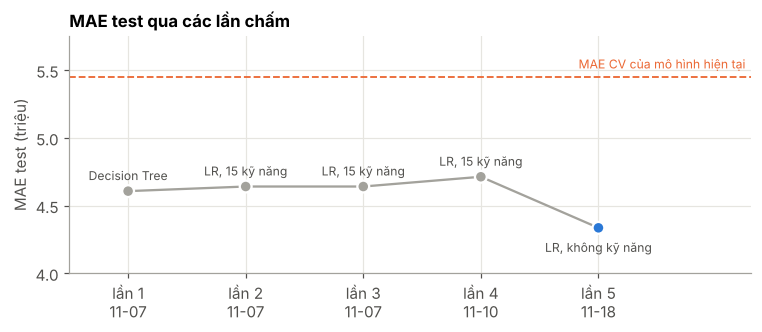

,lan,ngay,mo_hinh,params,mae_test,r2_test,ghi_chu
0,1,2026-11-07 14:11,decision_tree,"{""max_depth"": 4, ""min_samples_leaf"": 10}",4.607,0.506,"Commit 2e02c16. Grid DT/RF, chọn theo quy tắc 1-SE; tập sạch 449 tin"
1,2,2026-11-07 18:03,linear_regression,"{""skill_top_k"": 15}",4.641,0.534,"Commit 272edbf. Sau lần 1: đổi quy tắc 1-SE -> 1-SD, thêm LR và skill_top_k vào grid"
2,3,2026-11-07 20:02,linear_regression,"{""skill_top_k"": 15}",4.641,0.534,Commit ba050b0. Chạy lại cùng mô hình để thêm bảng MAE theo nhóm có baseline; kết quả không đổi
3,4,2026-11-10 04:14,linear_regression,"{""skill_top_k"": 15}",4.713,0.522,"Commit 399bb14. Sửa bộ lọc IT (456 tin, thêm 7 tin vào train); cùng 86 tin test"
4,5,2026-11-18 21:21,linear_regression,"{""experience"": ""numeric"", ""log_target"": false, ""skill_top_k"": 0}",4.336,0.580,src/evaluate.py --force


In [8]:
log = read("test_set_log.csv")
fig, ax = plt.subplots(figsize=(8, 2.8))
ax.plot(log.lan, log.mae_test, color=GRAY, lw=1.5, zorder=1)
ax.scatter(log.lan, log.mae_test, s=60, color=[BLUE if i == len(log) - 1 else GRAY for i in range(len(log))],
           edgecolor="white", lw=1.5, zorder=2)
def short(r):
    p = json.loads(r.params)
    if r.mo_hinh == "decision_tree":
        return "Decision Tree"
    return f"LR, {p.get('skill_top_k', 0)} kỹ năng" if p.get("skill_top_k", 0) else "LR, không kỹ năng"
for _, r in log.iterrows():
    below = r.lan == len(log)
    ax.text(r.lan, r.mae_test + (-0.09 if below else 0.06), short(r), ha="center", fontsize=8,
            color=MUTED, va="top" if below else "bottom")
ax.axhline(card["cv_metrics"]["mae_mean"], color=ORANGE, ls="--", lw=1.2)
ax.text(len(log) + 1.25, card["cv_metrics"]["mae_mean"] + 0.04, "MAE CV của mô hình hiện tại", color=ORANGE,
        fontsize=8, va="bottom", ha="right")
ax.set_xticks(log.lan, [f"lần {i}\n{d[5:10]}" for i, d in zip(log.lan, log.ngay)])
ax.set_xlim(0.5, len(log) + 1.3)
ax.set_ylim(4.0, card["cv_metrics"]["mae_mean"] + 0.3)
ax.set_ylabel("MAE test (triệu)")
ax.set_title("MAE test qua các lần chấm")
plt.show()
display(log[["lan", "ngay", "mo_hinh", "params", "mae_test", "r2_test", "ghi_chu"]])

## 6. Khoảng dự đoán ~80%

Khoảng được học từ phần dư out-of-fold trên train, có hai kiểu:

- **cộng:** mọi đầu vào nhận cùng độ rộng, khoảng ±8 triệu;
- **theo tỉ lệ (log):** lương dự đoán cao thì khoảng rộng hơn.

Cả hai đều phủ 80% tổng thể theo cách xây dựng. Kiểu nào phủ đều hơn ở ba mức lương dự đoán thấp/vừa/cao thì được chọn, và việc chọn chỉ dùng train.

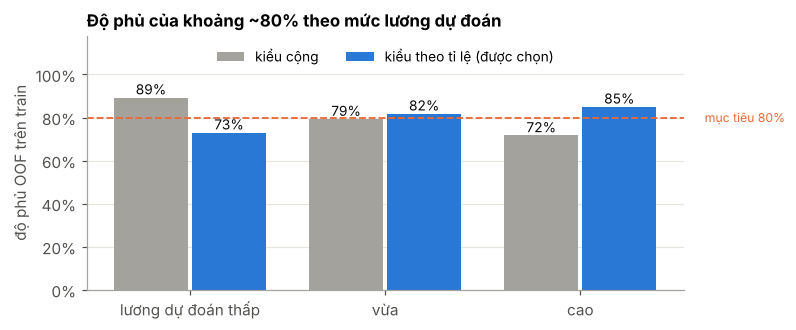

Dự đoán 10 triệu -> khoảng ~80%: 6.1–14.1 triệu (rộng 8.0)
Dự đoán 20 triệu -> khoảng ~80%: 12.5–27.9 triệu (rộng 15.3)
Dự đoán 35 triệu -> khoảng ~80%: 22.2–48.5 triệu (rộng 26.3)


In [9]:
diag = iv["diagnostics"]
fig, ax = plt.subplots(figsize=(7, 3))
x = np.arange(3)
w = 0.38
for k, (scale, color, label) in enumerate((("additive", GRAY, "kiểu cộng"), ("log", BLUE, "kiểu theo tỉ lệ (được chọn)"))):
    vals = diag[scale]["oof_tercile_coverage"]
    ax.bar(x + (k - 0.5) * (w + 0.02), vals, w, color=color, label=label)
    for xi, v in zip(x, vals):
        ax.text(xi + (k - 0.5) * (w + 0.02), v + 0.015, f"{v:.0%}", ha="center", fontsize=9, color=INK)
ax.axhline(0.8, color=ORANGE, ls="--", lw=1.2)
ax.text(2.62, 0.8, " mục tiêu 80%", color=ORANGE, fontsize=8, va="center")
ax.set_xticks(x, ["lương dự đoán thấp", "vừa", "cao"])
ax.set_ylim(0, 1.18)
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.set_ylabel("độ phủ OOF trên train")
ax.grid(axis="x", visible=False)
ax.legend(frameon=False, fontsize=9, loc="upper center", ncol=2)
ax.set_yticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])
ax.set_title("Độ phủ của khoảng ~80% theo mức lương dự đoán")
plt.show()

for s in (10, 20, 35):
    lo, hi = apply_interval(float(s), iv)
    print(f"Dự đoán {s:>2} triệu -> khoảng ~80%: {lo:.1f}–{hi:.1f} triệu (rộng {hi - lo:.1f})")

## 7. Đặc trưng nào quan trọng, mô hình sai ở đâu

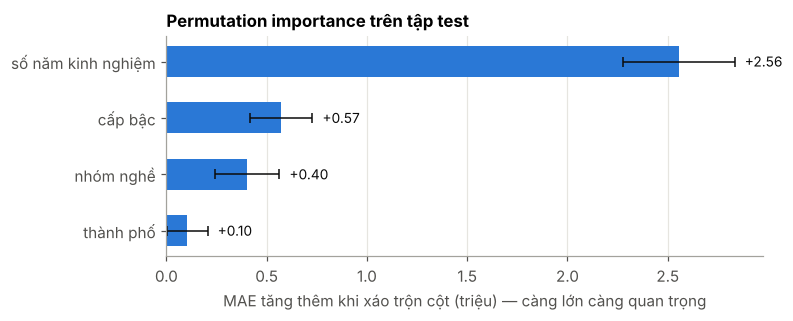

In [10]:
perm = read("gd5_permutation_importance.csv").sort_values("mae_increase")
names = {"experience_years": "số năm kinh nghiệm", "seniority_coarse": "cấp bậc",
         "job_category": "nhóm nghề", "city": "thành phố"}
fig, ax = plt.subplots(figsize=(7, 2.6))
ax.barh(perm.feature.map(names), perm.mae_increase, xerr=perm["std"], color=BLUE, height=0.55,
        error_kw={"ecolor": INK, "elinewidth": 1, "capsize": 3})
for i, r in enumerate(perm.itertuples()):
    ax.text(r.mae_increase + r.std + 0.05, i, f"+{r.mae_increase:.2f}", va="center", fontsize=9, color=INK)
ax.set_xlabel("MAE tăng thêm khi xáo trộn cột (triệu) — càng lớn càng quan trọng")
ax.grid(axis="y", visible=False)
ax.set_title("Permutation importance trên tập test")
plt.show()

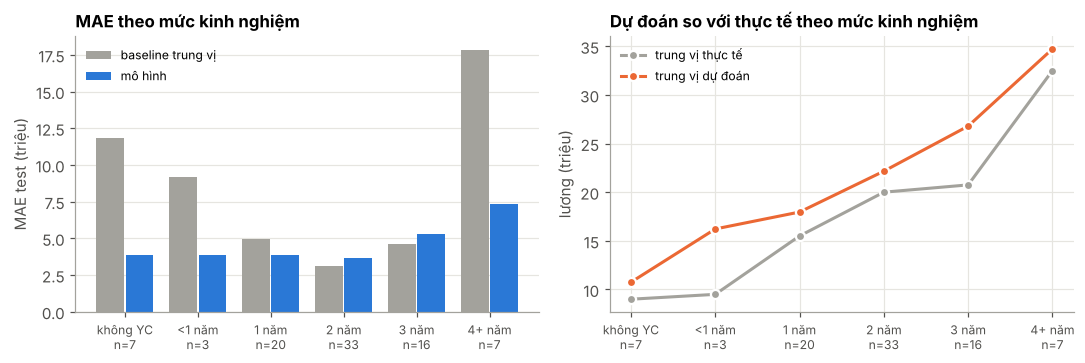

Nhóm có n < 10 chỉ để tham khảo, không kết luận.


In [11]:
gm = read("gd5_group_mae.csv")
d = gm[gm.column == "experience_group"].copy()
order = ["0 (không yêu cầu)", "<1 năm", "1 năm", "2 năm", "3 năm", "4+ năm"]
d = d.set_index("group").loc[[g for g in order if g in set(d.group)]].reset_index()
d["nhan"] = d.group.replace({"0 (không yêu cầu)": "không YC"})

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
x = np.arange(len(d))
w = 0.38
ax = axes[0]
ax.bar(x - w / 2 - 0.01, d.mae_dummy, w, color=GRAY, label="baseline trung vị")
ax.bar(x + w / 2 + 0.01, d.mae, w, color=BLUE, label="mô hình")
ax.set_xticks(x, [f"{g}\nn={n}" for g, n in zip(d.nhan, d.n)], fontsize=8)
ax.set_ylabel("MAE test (triệu)")
ax.grid(axis="x", visible=False)
ax.legend(frameon=False, fontsize=8)
ax.set_title("MAE theo mức kinh nghiệm")

ax = axes[1]
ax.plot(x, d.median_label, marker="o", color=GRAY, lw=2, label="trung vị thực tế",
        markeredgecolor="white", markeredgewidth=1.5)
ax.plot(x, d.median_pred, marker="o", color=ORANGE, lw=2, label="trung vị dự đoán",
        markeredgecolor="white", markeredgewidth=1.5)
ax.set_xticks(x, [f"{g}\nn={n}" for g, n in zip(d.nhan, d.n)], fontsize=8)
ax.set_ylabel("lương (triệu)")
ax.legend(frameon=False, fontsize=8)
ax.set_title("Dự đoán so với thực tế theo mức kinh nghiệm")
plt.tight_layout()
plt.show()
print("Nhóm có n < 10 chỉ để tham khảo, không kết luận.")

**Đọc kết quả:**

- **Số năm kinh nghiệm** là đặc trưng quan trọng nhất, quan trọng hơn hẳn các đặc trưng còn lại. Thành phố gần như không ảnh hưởng.
- **Mô hình dự đoán cao hơn thực tế** ở hầu hết các mức kinh nghiệm. Ở nhóm 2–3 năm, MAE còn cao hơn baseline. Nguyên nhân: hồi quy tuyến tính trên lương gốc dự đoán *giá trị trung bình*, trong khi lương lệch phải; thêm nữa, kinh nghiệm được mô hình hóa theo đường thẳng nên độ dốc bị các tin lương cao kéo lên.
- Log(lương), kinh nghiệm dạng nhóm hoặc hồi quy theo trung vị là các hướng khắc phục. Dự án **không đổi mô hình sau khi thấy kết quả này trên test**, để tránh chọn mô hình theo tập test.

## 8. Kết luận

- Mô hình được chọn là **Linear Regression** trên nhóm nghề, thành phố, số năm kinh nghiệm và cấp bậc, **không dùng kỹ năng**. Sai số kỳ vọng (nested CV) khoảng **5,45 triệu/tháng**, thấp hơn baseline trung vị (7,82) khoảng 30%.
- Các mô hình phức tạp hơn (Ridge, Decision Tree, Random Forest) không tốt hơn rõ, vì chênh lệch nhỏ hơn độ dao động giữa các fold.
- Kỹ năng trên tin tuyển dụng không giúp dự đoán với dữ liệu này.
- Giới hạn chính là **dữ liệu**: 370 tin train, tập trung ở Hà Nội và TP.HCM, kinh nghiệm 0–6 năm. Muốn cải thiện rõ cần thêm dữ liệu trước khi thêm mô hình.
- Kết quả chỉ mang tính tham khảo: nhãn là trung điểm khoảng lương **đăng tuyển**, không phải lương thực nhận.